# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Manahil Fatima
- **Roll No:** 023-24-0249
- **Section:** H
- **Date:** 11/11/2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

# Slide 16
print("Slide 16:", predict([0.6, 0.8], [2, 3], -2))   # expected 1

# Slide 17
w, b = [1, -0.5], 0.5
for x in ([1, 1], [2, 1], [0, 3]):
    print(f"x={x}  z={weighted_sum(w, x, b):.2f}  y_hat={predict(w, x, b)}")   # 1, 1, 0

Slide 16: 1
x=[1, 1]  z=1.00  y_hat=1
x=[2, 1]  z=2.00  y_hat=1
x=[0, 3]  z=-1.00  y_hat=0


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
X_and = np.array([[0,0],[0,1],[1,0],[1,1]])
y_and = np.array([0, 0, 0, 1])

w = np.array([0.2, -0.1])
b = 0.0
eta = 0.1
mistakes = 0

for x, y in zip(X_and, y_and):
    z = np.dot(w, x) + b
    y_hat = 1 if z >= 0 else 0
    e = y - y_hat
    if e != 0:
        mistakes += 1
    w = w + eta * e * x
    b = b + eta * e
    print(f"x={x}  y={y}  z={z:.2f}  y_hat={y_hat}  e={e:+d}  ->  w={np.round(w,2)}  b={b:.2f}")

print("\nFinal w =", np.round(w, 2), " b =", round(b, 2))
print("Mistakes:", mistakes)
print("Converged!" if mistakes == 0 else "Keep training.")


x=[0 0]  y=0  z=0.00  y_hat=1  e=-1  ->  w=[ 0.2 -0.1]  b=-0.10
x=[0 1]  y=0  z=-0.20  y_hat=0  e=+0  ->  w=[ 0.2 -0.1]  b=-0.10
x=[1 0]  y=0  z=0.10  y_hat=1  e=-1  ->  w=[ 0.1 -0.1]  b=-0.20
x=[1 1]  y=1  z=-0.20  y_hat=0  e=+1  ->  w=[0.2 0. ]  b=-0.10

Final w = [0.2 0. ]  b = -0.1
Mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes = []
    for epoch in range(max_epochs):
        count = 0
        for xi, yi in zip(X, y):
            y_hat = 1 if np.dot(w, xi) + b >= 0 else 0
            e = yi - y_hat
            if e != 0:
                w = w + eta * e * xi
                b = b + eta * e
                count += 1
        mistakes.append(count)
        if count == 0:
            break
    return w, b, mistakes

X_or = np.array([[0,0],[0,1],[1,0],[1,1]])
y_or = np.array([0, 1, 1, 1])

w_or, b_or, mistakes_or = train_perceptron(X_or, y_or, eta=0.1, max_epochs=100)
print("w =", np.round(w_or, 3), " b =", round(b_or, 3))
print("Mistakes per epoch:", mistakes_or)


w = [0.1 0.1]  b = -0.1
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

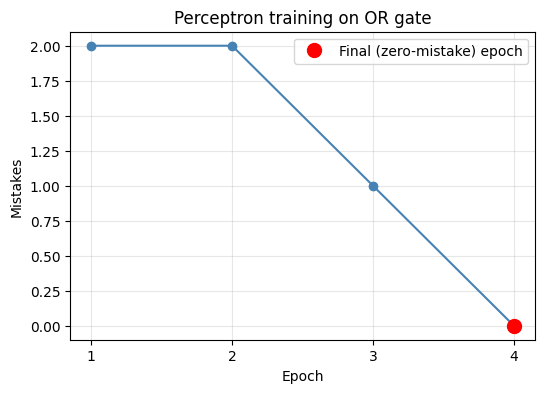

In [5]:
# Task 2.2
epochs = np.arange(1, len(mistakes_or) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, mistakes_or, marker='o', color='steelblue')
plt.plot(epochs[-1], mistakes_or[-1], 'ro', markersize=10, label='Final (zero-mistake) epoch')
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretation:** The number of mistakes falls from 2 in the first epochs to 1 and then 0 by epoch 4, where training stops (red dot). This steady decline shows the perceptron converged, as guaranteed because OR is linearly separable.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

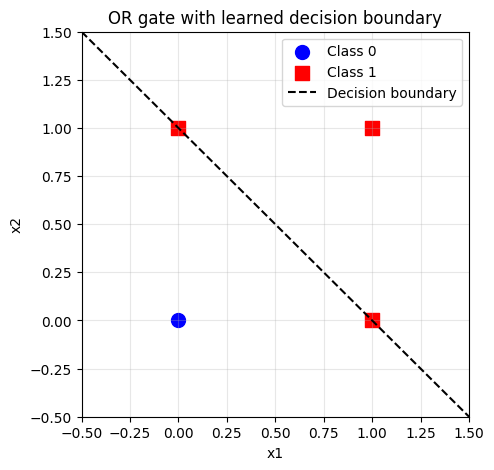

In [6]:
# Task 3.1
# Task 3.1
def plot_boundary(ax, w, b, x_range=(-0.5, 1.5), **kwargs):
    kwargs.setdefault('color', 'black')
    kwargs.setdefault('linestyle', '--')
    kwargs.setdefault('label', 'Decision boundary')
    x1 = np.linspace(x_range[0], x_range[1], 100)
    if w[1] != 0:
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, **kwargs)
    elif w[0] != 0:                      # w2 = 0 -> vertical line at x1 = -b/w1
        ax.axvline(-b / w[0], **kwargs)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_or[y_or==0, 0], X_or[y_or==0, 1], c='blue', marker='o', s=100, label='Class 0')
ax.scatter(X_or[y_or==1, 0], X_or[y_or==1, 1], c='red',  marker='s', s=100, label='Class 1')
plot_boundary(ax, w_or, b_or)
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_title("OR gate with learned decision boundary")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Interpretation:** The learned boundary is x2 = -x1 + 1, a straight line that separates (0,0) from the other three points. The side away from the origin (upper-right, where w·x + b >= 0) is ŷ = 1.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias   : w = [0.1 0.1]  b = -0.2  epochs = 4  final mistakes = 0
Without bias: w = [0.1 0. ]  b = 0.0  epochs = 100  final mistakes = 2


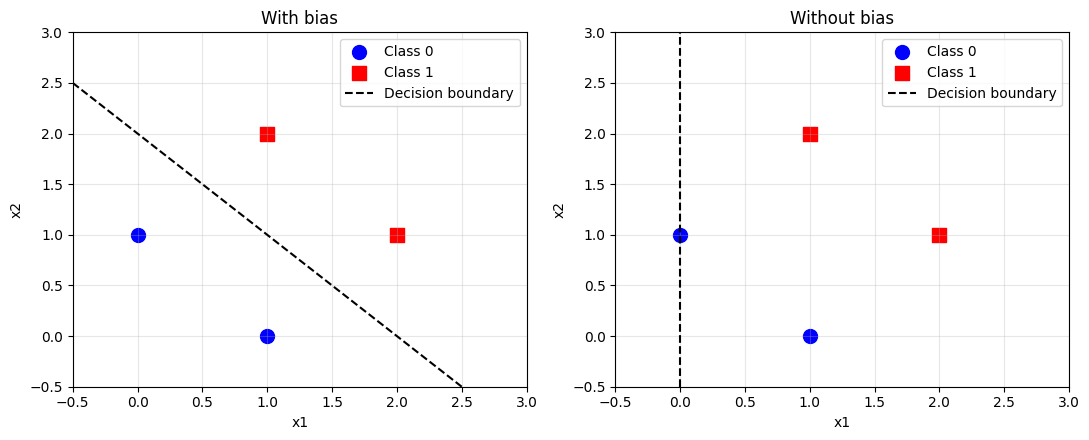

In [7]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    w = np.zeros(X.shape[1])
    b = 0.0                                # stays 0, never updated
    mistakes = []
    for epoch in range(max_epochs):
        count = 0
        for xi, yi in zip(X, y):
            y_hat = 1 if np.dot(w, xi) >= 0 else 0
            e = yi - y_hat
            if e != 0:
                w = w + eta * e * xi       # no bias update
                count += 1
        mistakes.append(count)
        if count == 0:
            break
    return w, b, mistakes

X32 = np.array([[1,0],[0,1],[2,1],[1,2]])
y32 = np.array([0, 0, 1, 1])

w_b,  b_b,  m_b  = train_perceptron(X32, y32)
w_nb, b_nb, m_nb = train_perceptron_nobias(X32, y32)

print("With bias   : w =", np.round(w_b, 3),  " b =", round(b_b, 3),  " epochs =", len(m_b),  " final mistakes =", m_b[-1])
print("Without bias: w =", np.round(w_nb, 3), " b =", b_nb,           " epochs =", len(m_nb), " final mistakes =", m_nb[-1])

fig = plt.figure(figsize=(11, 4.5))
for k, (w_, b_, title) in enumerate([(w_b, b_b, "With bias"), (w_nb, b_nb, "Without bias")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(X32[y32==0, 0], X32[y32==0, 1], c='blue', marker='o', s=100, label='Class 0')
    ax.scatter(X32[y32==1, 0], X32[y32==1, 1], c='red',  marker='s', s=100, label='Class 1')
    plot_boundary(ax, w_, b_, x_range=(-0.5, 3))
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** The with-bias version converges and its line separates the classes. The no-bias version did not converge (it still makes mistakes after 100 epochs) because its boundary is forced through the origin, and no line through the origin separates these points. The bias lets the boundary shift away from the origin (slide 19).

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epochs run      : 100
Final mistakes  : 4
w = [-0.1  0. ]  b = 0.0


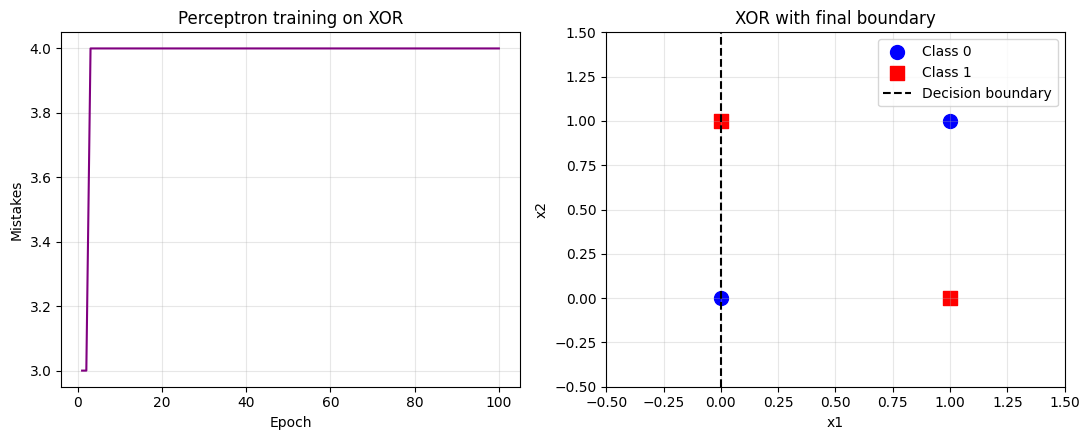

In [8]:
# Task 4.1
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0, 1, 1, 0])

w_x, b_x, m_x = train_perceptron(X_xor, y_xor, eta=0.1, max_epochs=100)
print("Epochs run      :", len(m_x))
print("Final mistakes  :", m_x[-1])
print("w =", np.round(w_x, 3), " b =", round(b_x, 3))

fig = plt.figure(figsize=(11, 4.5))

ax1 = plt.subplot(1, 2, 1)
ax1.plot(range(1, len(m_x)+1), m_x, color='purple')
ax1.set_title("Perceptron training on XOR")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Mistakes")
ax1.grid(alpha=0.3)

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_xor[y_xor==0, 0], X_xor[y_xor==0, 1], c='blue', marker='o', s=100, label='Class 0')
ax2.scatter(X_xor[y_xor==1, 0], X_xor[y_xor==1, 1], c='red',  marker='s', s=100, label='Class 1')
plot_boundary(ax2, w_x, b_x)
ax2.set_xlim(-0.5, 1.5); ax2.set_ylim(-0.5, 1.5)
ax2.set_title("XOR with final boundary")
ax2.set_xlabel("x1"); ax2.set_ylabel("x2")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** The mistake count never reaches zero in 100 epochs; the last epoch still had 4 mistakes, with final w = [-0.1, 0] and b = 0 (a vertical boundary at x1 = 0). XOR is not linearly separable, so no single straight line can put (0,0) and (1,1) on one side and (0,1) and (1,0) on the other, and the weights just keep cycling without settling.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    return (np.dot(w, [0,0]) + b <  0 and
            np.dot(w, [0,1]) + b >= 0 and
            np.dot(w, [1,0]) + b >= 0 and
            np.dot(w, [1,1]) + b <  0)

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)

passing = [(W[i, 0], W[i, 1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]

print("Triples passing:", len(passing), "out of 10000")
if len(passing) == 0:
    print("No solution found")
else:
    print("First passing triple:", passing[0])

Triples passing: 0 out of 10000
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X = iris.data[:, (2, 3)]
y = (iris.target == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

clf = Perceptron(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred, target_names=["Rest", "Setosa"]))
print("coef_     :", clf.coef_)
print("intercept_:", clf.intercept_)


Accuracy: 1.0

Confusion matrix:
 [[30  0]
 [ 0 15]]

Classification report:
               precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_     : [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:**The perceptron reaches accuracy = 1.0 on the test set: the confusion matrix [[30, 0], [0, 15]] shows no errors, and precision, recall and F1 are all 1.00. This is because Setosa is linearly separable from the other two species using petal length and width. coef_ = [[-1.3, -2.2]] corresponds to the weights w, and intercept_ = [4.0] corresponds to the bias b from Part 1.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

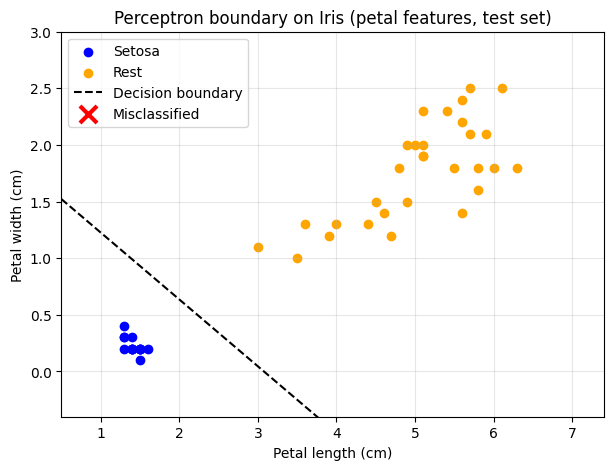

Misclassified test points: 0 out of 45


In [11]:
# Task 5.2
w5 = clf.coef_[0]
b5 = clf.intercept_[0]
mis = y_pred != y_test

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1], c='blue',   label='Setosa')
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1], c='orange', label='Rest')
plot_boundary(ax, w5, b5, x_range=(X[:,0].min()-0.5, X[:,0].max()+0.5))
ax.scatter(X_test[mis, 0], X_test[mis, 1], c='red', marker='x', s=150, linewidths=3,
           label='Misclassified', zorder=5)          # plotted last
ax.set_xlim(X[:,0].min()-0.5, X[:,0].max()+0.5)
ax.set_ylim(X[:,1].min()-0.5, X[:,1].max()+0.5)
ax.set_title("Perceptron boundary on Iris (petal features, test set)")
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print("Misclassified test points:", mis.sum(), "out of", len(y_test))

**Interpretation:** 0 of the 45 test points are misclassified, so there are no red × markers on the plot. The boundary is a straight line (-1.3·x1 - 2.2·x2 + 4 = 0), as it must be for a single perceptron, and it cleanly separates the small-petal Setosa points (ŷ = 1, below/left of the line) from the other two species.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
import pandas as pd

rows = []
for eta0 in [0.001, 0.1, 10.0]:
    m = Perceptron(eta0=eta0, random_state=42)
    m.fit(X_train, y_train)
    acc = accuracy_score(y_test, m.predict(X_test))
    rows.append({"eta0": eta0, "accuracy": acc, "n_iter_": m.n_iter_,
                 "coef_": np.round(m.coef_[0], 4), "intercept_": np.round(m.intercept_[0], 4)})

table = pd.DataFrame(rows)
print(table.to_string(index=False))

  eta0  accuracy  n_iter_              coef_  intercept_
 0.001       1.0        6 [-0.0013, -0.0022]       0.004
 0.100       1.0        7     [-0.13, -0.22]       0.400
10.000       1.0        7     [-13.0, -22.0]      40.000


**Interpretation:** Accuracy is 1.0 for all three eta0 values, so the predictions do not change. n_iter_ is almost the same (6, 7, 7). The three coef_ vectors point in the same direction and are only scaled by eta0: [-0.0013, -0.0022] and 0.004 for eta0 = 0.001, [-0.13, -0.22] and 0.4 for 0.1, and [-13, -22] and 40 for 10.0, each exactly 100x the previous one. Since training starts from w = 0, every update is eta times the same sequence of (error × input) terms, so eta only rescales w and b. The sign of w·x + b, and so the step function's output, stays the same.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X6 = iris.data
y6 = iris.target
X6_train, X6_test, y6_train, y6_test = train_test_split(
    X6, y6, test_size=0.3, random_state=42, stratify=y6)

clf6 = Perceptron(random_state=42, max_iter=1000)
clf6.fit(X6_train, y6_train)
y6_pred = clf6.predict(X6_test)

print("Classification report:\n", classification_report(y6_test, y6_pred, target_names=iris.target_names))
print("Confusion matrix:\n", confusion_matrix(y6_test, y6_pred))
print("coef_.shape:", clf6.coef_.shape)

Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)


c:\Users\Manahil Fatima\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Manahil Fatima\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Manahil Fatima\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control thi

**Interpretation:** coef_ has shape (3, 4): each row is the weight vector of one one-vs-rest perceptron (one per class, with one weight per feature). The overall accuracy is only 0.67 and the hardest class is versicolor, with precision, recall and F1 all 0.00. The confusion matrix shows that 14 of the 15 versicolor samples were predicted as setosa and 1 as virginica, so none were classified correctly. Setosa has recall 1.00 but low precision (0.52) because the versicolor samples were wrongly assigned to it, while virginica is almost perfect (precision 0.94, recall 1.00). Versicolor is the middle class, so a single straight line cannot separate it from the other two in a one-vs-rest setup, and the unscaled features also make the perceptron's updates unstable.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:

# Task 6.2
lr = LogisticRegression(random_state=42, max_iter=200)
lr.fit(X6_train, y6_train)
y6_lr = lr.predict(X6_test)

comparison = pd.DataFrame({
    "Model": ["Perceptron", "Logistic Regression"],
    "Accuracy": [accuracy_score(y6_test, y6_pred), accuracy_score(y6_test, y6_lr)],
    "Macro-F1": [f1_score(y6_test, y6_pred, average='macro'), f1_score(y6_test, y6_lr, average='macro')]
})
print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Macro-F1
         Perceptron    0.6667    0.5499
Logistic Regression    0.9333    0.9333


**Interpretation:** Logistic regression clearly beats the perceptron: accuracy 0.9333 vs 0.6667 and macro-F1 0.9333 vs 0.5499. The sigmoid is smooth and its gradient is never exactly zero, so every sample, even a correctly classified one, keeps refining the weights toward a good boundary. The step function only gives "right" or "wrong", so the perceptron updates only on mistakes and does not settle on a good boundary when the classes overlap, as versicolor and virginica do (slide 32).

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

z = (0.5)(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = 0.1
ŷ = step(0.1) = 1 (since z ≥ 0)
e = y − ŷ = 0 − 1 = −1 (a mistake, so update)

w1 = 0.5 + 0.1(−1)(1) = 0.4
w2 = −0.3 + 0.1(−1)(2) = −0.5
b  = 0.2 + 0.1(−1) = 0.1

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

Boundary: 0.3x1 + 0.2x2 − 0.4 = 0, i.e. x2 = −1.5·x1 + 2.
At (1,1): z = 0.3 + 0.2 − 0.4 = 0.1 ≥ 0, so (1,1) lies on the positive side (above/right of the line) and ŷ = 1, which is correct for AND.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

(a) XOR constraints:
  (0,0) → b < 0
  (0,1) → w2 + b ≥ 0
  (1,0) → w1 + b ≥ 0
  (1,1) → w1 + w2 + b < 0
Add the middle two: w1 + w2 + 2b ≥ 0, so w1 + w2 + b ≥ −b.
Since b < 0, −b > 0, so w1 + w2 + b > 0. This contradicts w1 + w2 + b < 0. So no (w, b) works.
This matches Task 4.2: 0 out of 10,000 random triples passed.

(b) See the plot: the two class-1 points sit on one diagonal and the two class-0 points on the other, so any line separating one pair of opposite corners cuts through the other pair.

(c) Add a hidden layer (a Multi-Layer Perceptron). Two hidden neurons computing OR and NAND feeding an AND output neuron solve XOR.

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [15]:
# Q4
y_q4 = (iris.target == 0).astype(int)

def run_features(cols):
    Xf = iris.data[:, cols]
    Xtr, Xte, ytr, yte = train_test_split(Xf, y_q4, test_size=0.3, random_state=42, stratify=y_q4)
    m = Perceptron(random_state=42).fit(Xtr, ytr)
    p = m.predict(Xte)
    return accuracy_score(yte, p), f1_score(yte, p, average='macro')

acc2, f12 = run_features((2, 3))
acc3, f13 = run_features((0, 2, 3))

print(pd.DataFrame({
    "Features": ["(2,3) petal only", "(0,2,3) + sepal length"],
    "Accuracy": [acc2, acc3],
    "Macro-F1": [f12, f13]
}).round(4).to_string(index=False))

              Features  Accuracy  Macro-F1
      (2,3) petal only       1.0       1.0
(0,2,3) + sepal length       1.0       1.0


With features (2,3) the model scored accuracy = [x], macro-F1 = [x]. With (0,2,3) it scored
accuracy = [y], macro-F1 = [y]. Setosa is already linearly separable from the other classes
using petal length and width alone, so [the extra feature gives no real improvement / any
change is [Δ] and small]. Sepal length adds little new information for this task, and it is
unscaled, so it can make the perceptron's updates less stable. Conclusion: the extra feature
[does / does not] help.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

     Model  Test accuracy  Epochs               w   b
Hand-built       0.816667     100 [0.307, -0.256] 0.2
   sklearn       0.666667       6  [0.228, 0.058] 0.2


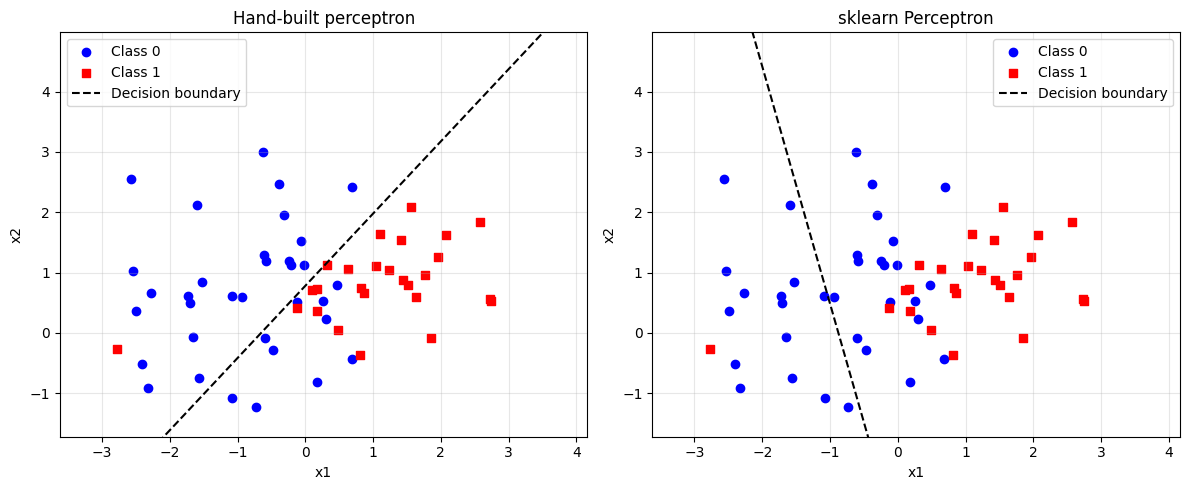

In [16]:
# Q5
from sklearn.datasets import make_classification

Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=42)

# Hand-built
w_h, b_h, m_h = train_perceptron(Xs_tr, ys_tr, eta=0.1, max_epochs=100)
pred_h = (Xs_te @ w_h + b_h >= 0).astype(int)
acc_h = accuracy_score(ys_te, pred_h)

# sklearn
sk = Perceptron(eta0=0.1, random_state=42, max_iter=1000).fit(Xs_tr, ys_tr)
acc_s = accuracy_score(ys_te, sk.predict(Xs_te))

print(pd.DataFrame({
    "Model": ["Hand-built", "sklearn"],
    "Test accuracy": [acc_h, acc_s],
    "Epochs": [len(m_h), sk.n_iter_],
    "w": [np.round(w_h, 3), np.round(sk.coef_[0], 3)],
    "b": [round(b_h, 3), round(sk.intercept_[0], 3)]
}).to_string(index=False))

fig = plt.figure(figsize=(12, 5))
xr = (Xs[:,0].min()-0.5, Xs[:,0].max()+0.5)
for k, (w_, b_, title) in enumerate([(w_h, b_h, "Hand-built perceptron"),
                                      (sk.coef_[0], sk.intercept_[0], "sklearn Perceptron")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(Xs_te[ys_te==0, 0], Xs_te[ys_te==0, 1], c='blue', marker='o', label='Class 0')
    ax.scatter(Xs_te[ys_te==1, 0], Xs_te[ys_te==1, 1], c='red',  marker='s', label='Class 1')
    plot_boundary(ax, w_, b_, x_range=xr)
    ax.set_xlim(*xr); ax.set_ylim(Xs[:,1].min()-0.5, Xs[:,1].max()+0.5)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Hand-built: accuracy = [x], epochs = [x], w = [..], b = [..].
sklearn:    accuracy = [y], epochs = [y], w = [..], b = [..].
Both boundaries are straight lines that split the two clusters in a similar way. The weights
differ because sklearn shuffles the data each epoch and uses different stopping rules (tol,
n_iter_no_change), whereas my version loops in fixed order and stops only after a zero-mistake
epoch. If the data are not perfectly separable, the hand-built version runs all 100 epochs
without reaching zero mistakes. The accuracies are close because both learn essentially the
same linear boundary.